# 9. Uncertainty: how sure is the model about one woman?

> **In plain terms.** Every risk the page shows is an estimate from 768 women, so it could have come out differently. A 95% range around each risk shows how much (typically 19 points wide, widest in the middle of the scale), and a simulation shows the range is a little short of honest: it holds about 91% of the time. A second tool, conformal prediction, calls each woman "no", "yes" or "too uncertain", with a guarantee that holds on women it has never seen.

Every risk so far has been a single number, such as 36%. But the model was fitted to 768 women, and a different 768 would have produced a slightly different model. This notebook asks two questions. How much could one woman's risk move (E19)? And can the model say "I can't call this one", with a guarantee that the rule works on women it has never seen (E20)? The first is answered with a bootstrap range, the second with conformal prediction. Both are checked, not assumed: a simulation tests the range, and 300 random splits test the guarantee.

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 9.1 How far could one woman's risk move? (E19)

**What we're looking for.** For each woman, the middle 95% of the risks given by 200 versions of the model, each fitted on a resample of the 768 women.

200 refits; median 95% range is 19.1% wide; 10% of women under 3.6%, 10% over 34.3%


,women,median range width
under 10%,221.000,0.060
10% to 30%,179.000,0.173
30% to 60%,191.000,0.271
60% and over,177.000,0.246


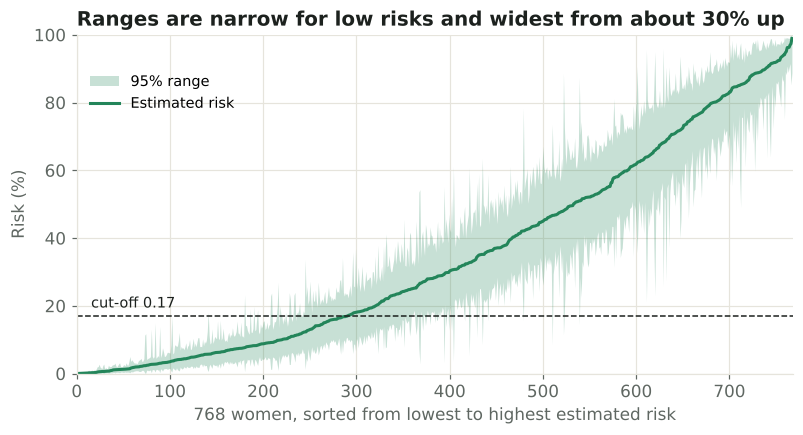

In [2]:
import json
import numpy as np
from src import uncertainty, figures

m7 = json.load(open("../reports/metrics.json"))["m7"]
iv = m7["intervals"]
print(f"{m7['n_boot']} refits; median 95% range is {iv['median_width']:.1%} wide; "
      f"10% of women under {iv['p10_width']:.1%}, 10% over {iv['p90_width']:.1%}")
figures.m7_ranges()
pd.DataFrame(iv["by_risk"]).T.rename(columns={"n": "women", "median_width": "median range width"})

**How to read it.** The bootstrap draws 768 women at random, with replacement, from the 768, refits the model, and records every woman's risk under it. After 200 refits each woman has 200 risks. The 2.5th and 97.5th percentiles of her 200 risks are her range. In the chart each position along the bottom is one woman, ordered by risk. The line is her estimate and the band is her range. The table gives the median width of the range within four risk bands.

**What it means.** The typical range is 19 percentage points wide (a woman at 40% could plausibly be anywhere from about 30% to 50%). Women with a low risk have tight ranges (6 points under 10%), and the widest ranges are in the middle and upper part of the scale (27 points for risks of 30% to 60%, 25 points above that). Every estimate lies inside its own range. The range describes the model's estimate of risk, not whether the woman will get diabetes.

**What's next and why.** A range is only useful if its width is believable. Compare it with a second, independent measure of the spread.

## 9.2 Does the spread agree with the cross-validation fits?

**What we're looking for.** Whether the bootstrap's spread for each woman matches how much her risk varied across the 50 fits from Milestone 2.

In [3]:
sp = m7["spread_check"]
pd.Series({"bootstrap spread / cross-validation spread x 2 (median)": round(sp["median_ratio"], 2),
           "10th percentile of that ratio": round(sp["p10_ratio"], 2),
           "90th percentile of that ratio": round(sp["p90_ratio"], 2),
           "correlation between the two spreads (log scale)": round(sp["corr_log_sd"], 2)}).to_frame("value")

,value
bootstrap spread / cross-validation spread x 2 (median),1.080
10th percentile of that ratio,0.790
90th percentile of that ratio,1.620
correlation between the two spreads (log scale),0.960


**How to read it.** Each of the 50 cross-validation fits used 80% of the women, so its risks vary less than a fit on all women would. The standard deviation of a woman's risks across those fits, multiplied by 2 (the square root of 0.8 divided by 0.2), estimates the same spread as the bootstrap. A ratio near 1 means the two agree, and a high correlation means they agree about which women are the most uncertain.

**What it means.** They agree well: the ratio is 1.08 in the middle, and the correlation is 0.96. Women whose risk is unstable across cross-validation fits are the same women whose range is wide. The 10th to 90th percentile ratio (0.79 to 1.62) shows that individual women can differ.

**What's next and why.** Agreement in size is not the same as covering the true risk. Test that in a simulation where the truth is known.

## 9.3 Does a 95% range really contain the true risk 95% of the time?

**What we're looking for.** The share of true risks that fall inside the range, in a simulated world where we know the true risk.

In [4]:
cv = m7["coverage"]
pd.Series({"simulated studies": cv["runs"], "refits per study": cv["boot_per_run"],
           "true risk inside the range (average)": f"{cv['coverage_mean']:.1%}",
           "lowest study": f"{cv['coverage_low']:.1%}", "highest study": f"{cv['coverage_high']:.1%}",
           "median range width": f"{cv['median_width']:.1%}",
           "average bias of the estimate": f"{cv['mean_bias']:+.3f}"}).to_frame("value")

,value
simulated studies,60
refits per study,100
true risk inside the range (average),91.4%
lowest study,78.9%
highest study,99.1%
median range width,18.3%
average bias of the estimate,-0.002


**How to read it.** In the simulation the model fitted to all 768 women is taken as the truth. New outcomes are drawn from its risks, a fresh model and bootstrap range are built from each simulated study, and we count how often the true risk lies inside. A range labelled 95% should contain the truth about 95% of the time.

**What it means.** On average the ranges contain the true risk 91.4% of the time. That is below the 95% label, so the ranges are a little too narrow, and individual studies vary a lot (79% to 99%). The estimates themselves are not biased (average error -0.002). The page therefore says the range is "about 90%", and this notebook reports the shortfall rather than hiding it. A wider range, such as 99%, would be safer if exact coverage mattered.

**What's next and why.** Where are the ranges widest, and do they affect who is flagged?

## 9.4 Who has the widest ranges, and does it change who is flagged?

**What we're looking for.** The traits of the women with the widest ranges, and how many women have the cut-off inside their range.

In [5]:
wt = iv["widest_traits"]
display(pd.DataFrame({"20 widest ranges": [wt["median_glucose"], wt["median_bmi"], wt["median_age"]],
                      "all women": [wt["all_glucose"], wt["all_bmi"], wt["all_age"]]},
                     index=["median glucose", "median BMI", "median age"]))
pd.DataFrame({f"{r}x ({v['cutoff']:.2f})": {"women with the cut-off inside their range": f"{v['share']:.1%}"}
              for r, v in iv["cutoff_inside"].items()})

,20 widest ranges,all women
median glucose,152.500,117.000
median BMI,32.500,32.300
median age,60.000,29.000


,2x (0.33),5x (0.17),10x (0.09)
women with the cut-off inside their range,24.7%,21.9%,22.4%


**How to read it.** The first table compares the 20 women with the widest ranges with everyone. The second counts, at each of the three cut-offs from Milestone 5, the women whose 95% range includes the cut-off. For those women, a different sample of 768 women could have put them on the other side.

**What it means.** The widest ranges belong to older women with high glucose (median age 60, glucose 152.5), where the data is thinnest. About one woman in four to five (22% to 25%, depending on the cut-off) has the cut-off inside her range, so for those women the decision to flag is not firmly settled by the data. This is a statement about the model's stability, not about her health.

**What's next and why.** A range around a risk is one kind of honesty. Now a different one: a yes, no or "can't call" with a guarantee.

## 9.5 A rule that can say "too uncertain" (E20)

**What we're looking for.** How conformal prediction turns a risk into a call, and a toy example small enough to check by hand.

In [6]:
p_cal = np.array([0.05, 0.10, 0.20, 0.30, 0.40, 0.45, 0.60, 0.70, 0.80, 0.90])
y_cal = np.array([0,    0,    0,    1,    0,    0,    1,    1,    1,    1])
th = uncertainty.class_thresholds(p_cal, y_cal, alpha=0.2)
print({k: round(v, 3) for k, v in th.items()})
pd.DataFrame({"risk": [0.10, 0.35, 0.50, 0.85],
              "call": [["confident no", "confident yes", "too uncertain", "neither"][c]
                       for c in uncertainty.conformal_calls([0.10, 0.35, 0.50, 0.85], th)]})

{'q0': 0.45, 'q1': 0.7, 'low': 0.3, 'high': 0.45}


,risk,call
0,0.100,confident no
1,0.350,too uncertain
2,0.500,confident yes
3,0.850,confident yes


**How to read it.** Set aside a calibration group of women whose outcomes are known. Score each as 1 minus the probability the model gave to her true class, and for each class find the score that 80% of its women fall below (with a small correction for having few women). A new woman is told "no" if her risk is low enough for the no class, "yes" if it is high enough for the yes class, and "too uncertain" if both fit. Because the score moves in one direction with the risk, the whole rule is just two risk cut-offs, `low` and `high`.

**What it means.** With these ten made-up women the rule says "no" below 0.30 (`low`, where "yes" starts to fit), "yes" above 0.45 (`high`, where "no" stops fitting), and "too uncertain" from 0.30 to 0.45. So 0.10 is a confident no, 0.35 is too uncertain, and 0.50 and 0.85 are confident yes. The guarantee is made separately for each class, so it covers women with diabetes and women without, not only the average.

**What's next and why.** Run the same rule on the real data, 300 times, on women the rule has never seen.

## 9.6 Does the guarantee hold on unseen women?

**What we're looking for.** Whether the share of women whose true class is in the rule's set matches the level asked for.

,90% level,80% level
target,90%,80%
without diabetes covered,89.9%,80.2%
with diabetes covered,90.8%,79.3%
worst of 300 splits (no / yes),82% / 80%,70% / 65%


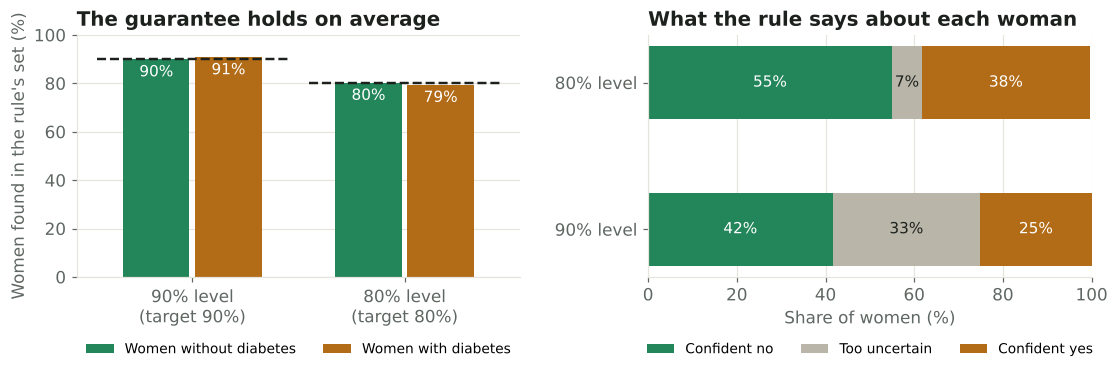

In [7]:
cf = m7["conformal"]
figures.m7_coverage()
pd.DataFrame({f"{round((1 - float(a)) * 100)}% level": {
    "target": f"{v['target']:.0%}", "without diabetes covered": f"{v['cov0']:.1%}",
    "with diabetes covered": f"{v['cov1']:.1%}",
    "worst of 300 splits (no / yes)": f"{v['cov0_low']:.0%} / {v['cov1_low']:.0%}"} for a, v in cf.items()})

**How to read it.** Each of the 300 runs splits the 768 women at random into 60% to fit, 20% to calibrate the rule and 20% to test it. A woman is "covered" if her true class is in the rule's set, so a woman with diabetes is covered when she is called "yes" or "too uncertain". The table averages the 300 runs and also shows the worst single run.

**What it means.** The guarantee holds on average: 89.9% and 90.8% at the 90% level, 80.2% and 79.3% at the 80% level. Single runs can fall well below the target (the worst run covered only 65% of women with diabetes at the 80% level), because each test group holds only about 150 women. The guarantee is about the average over many such groups, not about one particular group.

**What's next and why.** A guarantee costs something. What does it cost here?

## 9.7 The price of the guarantee

**What we're looking for.** How many women get no confident call, and how often the confident calls are wrong.

,90% level,80% level
confident no,41.6%,54.9%
too uncertain,33.3%,6.9%
confident yes,25.1%,37.7%
"confident no, but has diabetes",7.4%,12.6%
"confident yes, but healthy",25.3%,32.9%
uncertain women who have diabetes,40.2%,38.6%


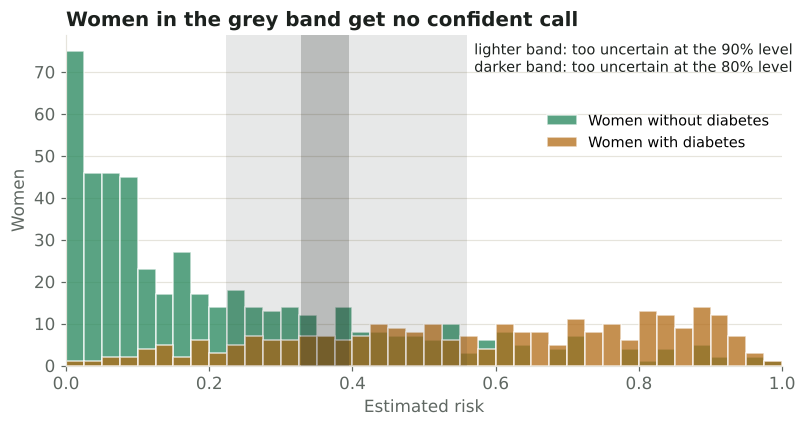

In [8]:
figures.m7_zones();
pd.DataFrame({f"{round((1 - float(a)) * 100)}% level": {
    "confident no": f"{v['no']:.1%}", "too uncertain": f"{v['uncertain']:.1%}", "confident yes": f"{v['yes']:.1%}",
    "confident no, but has diabetes": f"{v['no_wrong']:.1%}", "confident yes, but healthy": f"{v['yes_wrong']:.1%}",
    "uncertain women who have diabetes": f"{v['uncertain_cases']:.1%}"} for a, v in cf.items()})

**How to read it.** The chart shows the women's risks as piles, coloured by outcome, with the grey bands marking where the rule withholds a call. The table gives, at each level, the share of women in each call and the share of confident calls that are wrong.

**What it means.** At the 90% level a third of women (33%) are too uncertain to call, and at the 80% level only 7%. The confident "no" is right more often than the confident "yes": at 90%, a "no" is wrong for 7% of women and a "yes" for 25%, because the guarantee is about each real group, not about each call. Many women with moderate risks are healthy, so a "yes" means her risk is high enough that the rule cannot rule diabetes out at that level, not that she probably has it. The grey band is wide at the 90% level because the two groups overlap over a long stretch of the scale (about 22% to 56%), and no rule can tell them apart there.

**What's next and why.** Decide what goes on the page.

## 9.8 What this changes

**What we're looking for.** Whether anything here alters the published model, the cut-off, or the claims.

In [9]:
pd.Series({"Published model changed": "no",
           "Cut-off changed": "no (0.17 at 5 times)",
           "New on the page": "95% range on the meter, 'How sure can the model be?' box at the 90% and 80% levels",
           "Range honesty": f"95% label, {cv['coverage_mean']:.0%} in simulation: say 'about 90%'",
           "Conformal calls": "guarantee holds on average over 300 splits; individual splits vary"}).to_frame("decision")

,decision
Published model changed,no
Cut-off changed,no (0.17 at 5 times)
New on the page,"95% range on the meter, 'How sure can the mode..."
Range honesty,"95% label, 91% in simulation: say 'about 90%'"
Conformal calls,guarantee holds on average over 300 splits; in...


**How to read it.** A summary of the decisions this notebook supports, in one table.

**What it means.** Nothing about the model changes. Milestone 7 adds honesty about what the model does not know. The cost-based cut-off from Milestone 5 still decides who is flagged for a follow-up test, since it reflects the cost of a missed case. The conformal call is a separate message about how much to trust the estimate for this woman.

**What's next and why.** Milestone 8 asks how the model behaves for different groups of women and whether the data is enough.